#### Here use MobileNetV to train model and there use first 10 epochs as fixed feature extractor method and after 40 epochs use nomal fine tuning and but also we can improve output by increasing image size from 64x64 to larger value. I used first 10 epochs as fixed fetures because this dataset is too much small. and also we can do some argumentations and increase dataset to get better result but it take higer computational power.

Device: xpu
Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Train: 3326  Val: 713  Test: 713
[head] Epoch 1 | train loss 1.8833 | val loss 1.6500 | train acc 0.3575 | val acc 0.4895
[head] Epoch 2 | train loss 1.6310 | val loss 1.5305 | train acc 0.4880 | val acc 0.5610
[head] Epoch 3 | train loss 1.5724 | val loss 1.5034 | train acc 0.5141 | val acc 0.5568
[head] Epoch 4 | train loss 1.5564 | val loss 1.4888 | train acc 0.5268 | val acc 0.5582
[head] Epoch 5 | train loss 1.5257 | val loss 1.4669 | train acc 0.5295 | val acc 0.5624
[head] Epoch 6 | train loss 1.5239 | val loss 1.4787 | train acc 0.5481 | val acc 0.5540
[head] Epoch 7 | train loss 1.5108 | val loss 1.4514 | train acc 0.5574 | val acc 0.5680
[head] Epoch 8 | train loss 1.4934 | val loss 1.4482 | train acc 0.5562 | val acc 0.5554
[head] Epoch 9 | train loss 1.5019 | val loss 1.4644 | train acc 0.5412 | val acc 0.5596
[head] Epoch 10 | trai

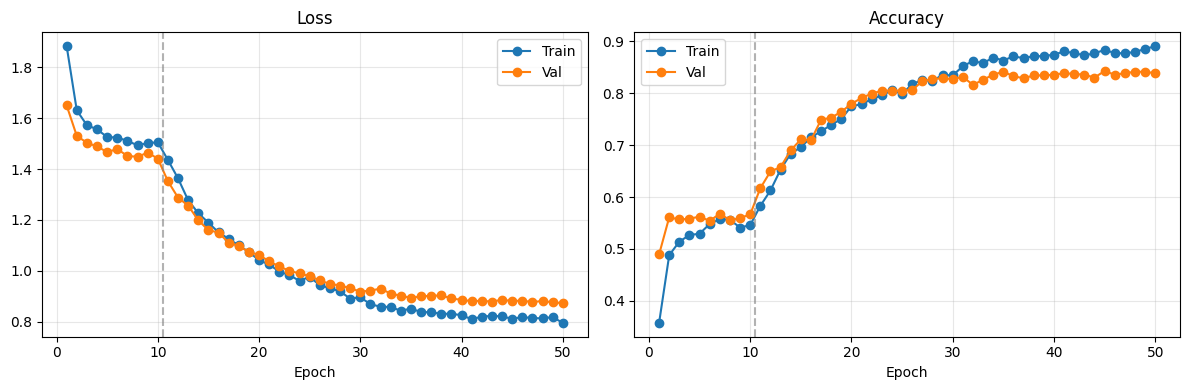


Test accuracy: 0.8485
Test macro F1: 0.8576
                     precision    recall  f1-score   support

          Cardboard     0.9242    0.8841    0.9037        69
      Food Organics     0.9180    0.9032    0.9106        62
              Glass     0.9455    0.8254    0.8814        63
              Metal     0.7970    0.8983    0.8446       118
Miscellaneous Trash     0.7606    0.7200    0.7397        75
              Paper     0.9077    0.7867    0.8429        75
            Plastic     0.7703    0.8261    0.7972       138
      Textile Trash     0.8696    0.8333    0.8511        48
         Vegetation     0.9265    0.9692    0.9474        65

           accuracy                         0.8485       713
          macro avg     0.8688    0.8496    0.8576       713
       weighted avg     0.8523    0.8485    0.8487       713



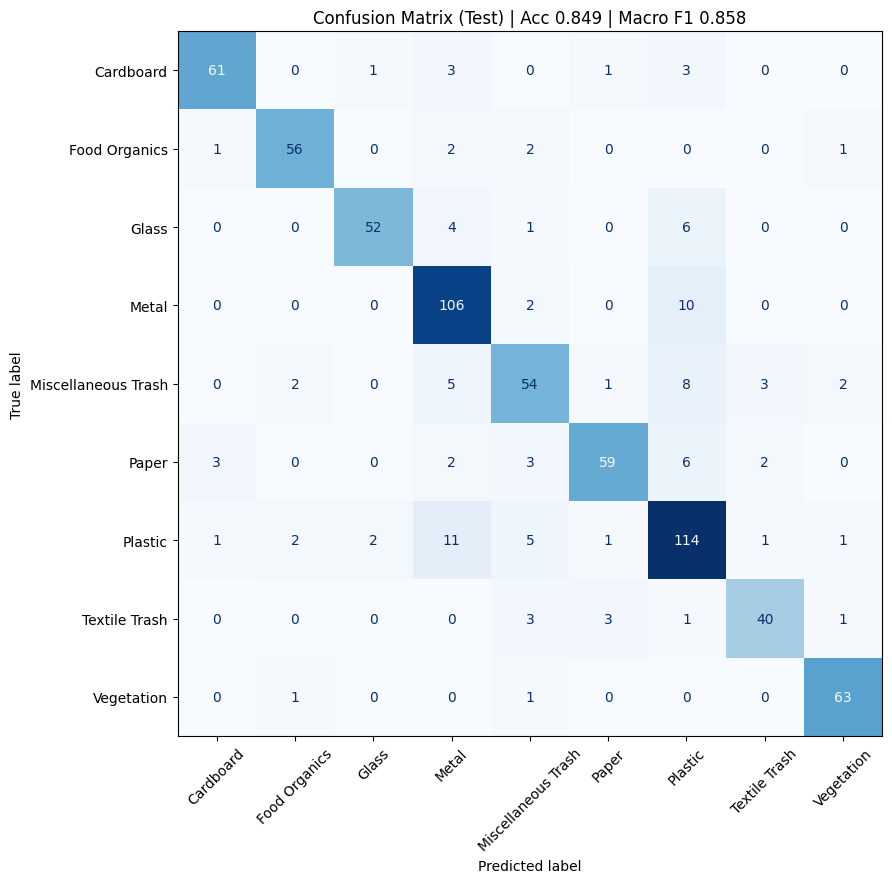

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, classification_report)

DATA_DIR = "RealWaste"
IMG_SIZE = 64            
BATCH_SIZE = 32
EPOCHS_HEAD = 10           
EPOCHS_FT = 40            
LR_HEAD = 1e-3
LR_FT = 1e-4              
SEED = 42
if torch.cuda.is_available():
    device = "cuda"
elif hasattr(torch, "xpu") and torch.xpu.is_available():
    device = "xpu"
else:
    device = "cpu"
print("Device:", device)
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(), norm,
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), norm,
])

train_full = datasets.ImageFolder(DATA_DIR, transform=train_tf)
eval_full = datasets.ImageFolder(DATA_DIR, transform=eval_tf)
classes = train_full.classes
targets = train_full.targets
print("Classes:", classes)

all_idx = list(range(len(targets)))
train_idx, temp_idx = train_test_split(
    all_idx, test_size=0.30, stratify=targets, random_state=SEED)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, stratify=[targets[i] for i in temp_idx],
    random_state=SEED)

train_ds = Subset(train_full, train_idx)
val_ds = Subset(eval_full, val_idx)
test_ds = Subset(eval_full, test_idx)
print(f"Train: {len(train_ds)}  Val: {len(val_ds)}  Test: {len(test_ds)}")

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, num_workers=2)

model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
model.classifier = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(model.last_channel, len(classes)),
)
model = model.to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)


def evaluate(loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    preds_all, labels_all = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * y.size(0)
            p = out.argmax(1)
            correct += (p == y).sum().item()
            total += y.size(0)
            preds_all.extend(p.cpu().tolist())
            labels_all.extend(y.cpu().tolist())
    return total_loss / total, correct / total, preds_all, labels_all


history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val = 0.0


def run_phase(epochs, optimizer, scheduler=None, tag=""):
    global best_val
    for _ in range(epochs):
        model.train()
        run_loss, run_correct = 0.0, 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * y.size(0)
            run_correct += (out.argmax(1) == y).sum().item()
        if scheduler:
            scheduler.step()

        tl, ta = run_loss / len(train_ds), run_correct / len(train_ds)
        vl, va, _, _ = evaluate(val_dl)
        for k, v in zip(history, (tl, vl, ta, va)):
            history[k].append(v)
        n = len(history["val_acc"])
        print(f"[{tag}] Epoch {n} | train loss {tl:.4f} | val loss {vl:.4f} "
              f"| train acc {ta:.4f} | val acc {va:.4f}")

        if va > best_val:
            best_val = va
            torch.save(model.state_dict(), "best_mobilenet_v2.pth")


for p in model.features.parameters():
    p.requires_grad = False
opt1 = torch.optim.AdamW(model.classifier.parameters(), lr=LR_HEAD, weight_decay=1e-4)
run_phase(EPOCHS_HEAD, opt1, tag="head")

for p in model.parameters():
    p.requires_grad = True
opt2 = torch.optim.AdamW(model.parameters(), lr=LR_FT, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=EPOCHS_FT)
run_phase(EPOCHS_FT, opt2, sched, tag="finetune")

total_epochs = EPOCHS_HEAD + EPOCHS_FT
ep = range(1, total_epochs + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (k1, k2, title) in zip(ax, [("train_loss", "val_loss", "Loss"),
                                   ("train_acc", "val_acc", "Accuracy")]):
    a.plot(ep, history[k1], marker="o", label="Train")
    a.plot(ep, history[k2], marker="o", label="Val")
    a.axvline(EPOCHS_HEAD + 0.5, color="gray", linestyle="--", alpha=0.6)  # unfreeze point
    a.set_title(title)
    a.set_xlabel("Epoch")
    a.legend()
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("training_curves_v2.png", dpi=150)
plt.show()

model.load_state_dict(torch.load("best_mobilenet_v2.pth", map_location=device))
model.eval()
preds, labels = [], []
with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)
        logits = model(x).softmax(1) + model(torch.flip(x, dims=[3])).softmax(1)
        preds.extend(logits.argmax(1).cpu().tolist())
        labels.extend(y.tolist())

acc = sum(p == l for p, l in zip(preds, labels)) / len(labels)
macro_f1 = f1_score(labels, preds, average="macro")
print(f"\nTest accuracy: {acc:.4f}")
print(f"Test macro F1: {macro_f1:.4f}")
print(classification_report(labels, preds, target_names=classes, digits=4))

cm = confusion_matrix(labels, preds)
fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"Confusion Matrix (Test) | Acc {acc:.3f} | Macro F1 {macro_f1:.3f}")
plt.tight_layout()
plt.show()